# AccordLens: Preference Alignment & Judge Reliability

An executed walkthrough of measured Qwen adaptation, human/GPT-4 evaluator reliability, and bilingual support token costs. This notebook reads released evidence and verifies core mathematics without model downloads or retraining.

In [1]:
import json
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Image, display

from accordlens.objectives import dpo_loss, gae, orpo_loss

ROOT = Path.cwd()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent


def read(path):
    return json.loads((ROOT / path).read_text())


summary = read("reports/experiment_summary.json")
summary["config"]

{'seed': 42,
 'model_id': 'Qwen/Qwen2.5-0.5B-Instruct',
 'model_revision': '7ae557604adf67be50417f59c2c2f167def9a775',
 'dataset_revision': '09be8c5bbc57cb3887f3a9732ad6aa7ec602a1fa',
 'train_pairs': 48,
 'validation_pairs': 16,
 'test_pairs': 32,
 'max_length': 256,
 'steps': 20,
 'learning_rate': 0.0002,
 'lora_rank': 4,
 'lora_alpha': 8,
 'beta': 0.1,
 'orpo_weight': 0.1,
 'ppo_rollouts': 6,
 'ppo_epochs': 3,
 'ppo_max_new_tokens': 24,
 'ppo_kl_coefficient': 0.02,
 'ppo_learning_rate': 2e-05,
 'judge_cases_per_source': 12,
 'judge_max_input_tokens': 1536,
 'judge_max_new_tokens': 8}

## Data isolation

Full dialogue history is preserved. Eligibility rejects overlength sequences rather than truncating away the response. Train/validation come from the official training source; test comes from the official test source. This favors short conversations and limits generalization.

In [2]:
manifest = pd.DataFrame(read("data/split_manifest.json"))
assert manifest["id"].nunique() == len(manifest)
assert manifest["prompt_id"].nunique() == len(manifest)
display(manifest.groupby("split").size().rename("pairs"))
read("reports/source_verification.json")

split
test          32
train         48
validation    16
Name: pairs, dtype: int64

{'public_split_manifest_matches_local': True,
 'public_judge_cases_match_local': True,
 'provided_gpt4_export_matches_first_1000_official_rows': True,
 'original_export_profile': {'sources': {'train': {'sha256': '882ef8cd8bcb57897ea0d0aee8b741b8d575c906df4ffc576d392cf3be75ef51',
    'format': '.arrow'},
   'test': {'sha256': 'fefc474c614179327be8864de85737e30ce8942f9997b43d813f79d164a615ab',
    'format': '.arrow'}},
  'diagnostics': {'train': {'source_rows': 160800,
    'unique_valid_pairs': 159384,
    'invalid_pairs': 1416},
   'test': {'source_rows': 8552,
    'unique_valid_pairs': 8475,
    'invalid_pairs': 77}},
  'cross_split_prompt_count': 69,
  'length_rejections_before_selection': {'train': 46, 'test': 20},
  'selection': 'Ascending SHA256 pair identifier; first eligible unique prompts after cross-source prompt exclusion, complete native chat sequences <=256 tokens',
  'human_parquet_sha256': '4877bc46a40929f4082c3c79593700fb897b1d6c7f4c473032694a01322f5769',
  'reference_xls

## Held-out policy diagnostics

Mean-token likelihood ranking and response NLL are descriptive metrics. They do not prove generated-answer helpfulness. DPO optimizes reference-relative summed log probabilities; ORPO uses mean-token odds. The small run establishes no preference-ranking gain.

,n,mean_logp_accuracy,ci95,mean_margin,chosen_nll,sum_logp_accuracy
base,32,0.53125,"[0.3644951711897464, 0.6913061289193116]",-0.148786,2.853097,0.53125
sft,32,0.53125,"[0.3644951711897464, 0.6913061289193116]",-0.069085,2.324202,0.5625
dpo,32,0.5,"[0.33630882869327483, 0.6636911713067252]",-0.103996,2.372554,0.5625
orpo,32,0.53125,"[0.3644951711897464, 0.6913061289193116]",-0.062861,2.319031,0.5625
ppo,32,0.53125,"[0.3644951711897464, 0.6913061289193116]",-0.06689,2.320839,0.5625


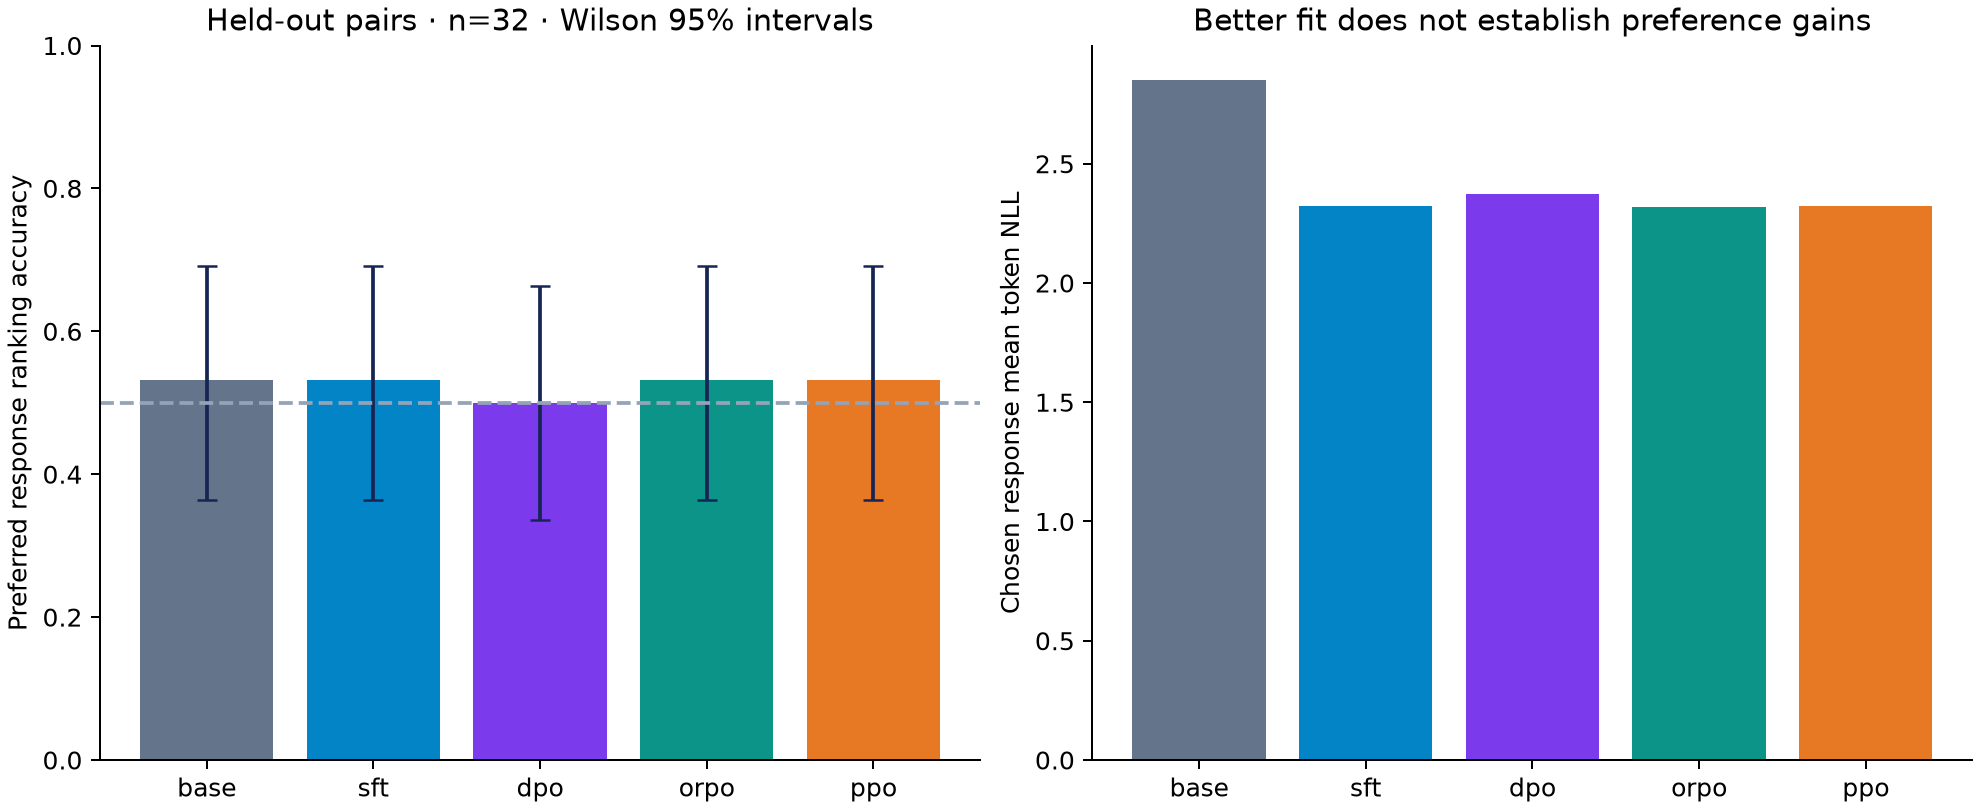

{'dpo': {'accuracy_difference_vs_sft': -0.03125,
  'paired_bootstrap_ci95': [-0.09375, 0.0],
  'resamples': 10000,
  'seed': 42},
 'orpo': {'accuracy_difference_vs_sft': 0.0,
  'paired_bootstrap_ci95': [0.0, 0.0],
  'resamples': 10000,
  'seed': 42},
 'ppo': {'accuracy_difference_vs_sft': 0.0,
  'paired_bootstrap_ci95': [0.0, 0.0],
  'resamples': 10000,
  'seed': 42}}

In [3]:
display(pd.DataFrame(summary["test"]).T)
display(Image(filename=str(ROOT / "reports/figures/preference_quality.png")))
read("reports/paired_comparisons.json")

## Objective sanity checks

At identical policy/reference likelihoods, DPO loss equals log(2). ORPO retains gradients even for unlikely responses. GAE gives the terminal reward to earlier tokens when gamma=lambda=1 and the critic is zero.

In [4]:
chosen = torch.tensor([-4.0], requires_grad=True)
rejected = torch.tensor([-5.0], requires_grad=True)
loss, margin = dpo_loss(chosen, rejected, chosen.detach(), rejected.detach())
loss.backward()
print(
    "DPO initial loss:",
    loss.item(),
    "gradient signs:",
    chosen.grad.item(),
    rejected.grad.item(),
)
assert chosen.grad.item() < 0 < rejected.grad.item()
low_chosen = torch.tensor([-30.0], requires_grad=True)
low_rejected = torch.tensor([-35.0], requires_grad=True)
orpo, _, _ = orpo_loss(low_chosen, low_rejected)
orpo.backward()
assert low_rejected.grad.item() != 0
advantages, returns = gae(torch.tensor([0.0, 0.0, 2.0]), torch.zeros(3), lam=1)
assert torch.equal(returns, torch.tensor([2.0, 2.0, 2.0]))
returns

DPO initial loss: 0.6931471824645996 gradient signs: -0.05000000074505806 0.05000000074505806


tensor([2., 2., 2.])

## Reward generalization and PPO

The reward head uses frozen SFT representations and validation checkpoint selection. Its test interval spans chance. PPO uses exact rollout density, fixed old probabilities, multiple clipped updates, a critic and GAE. Its small rollout budget cannot establish robust alignment.

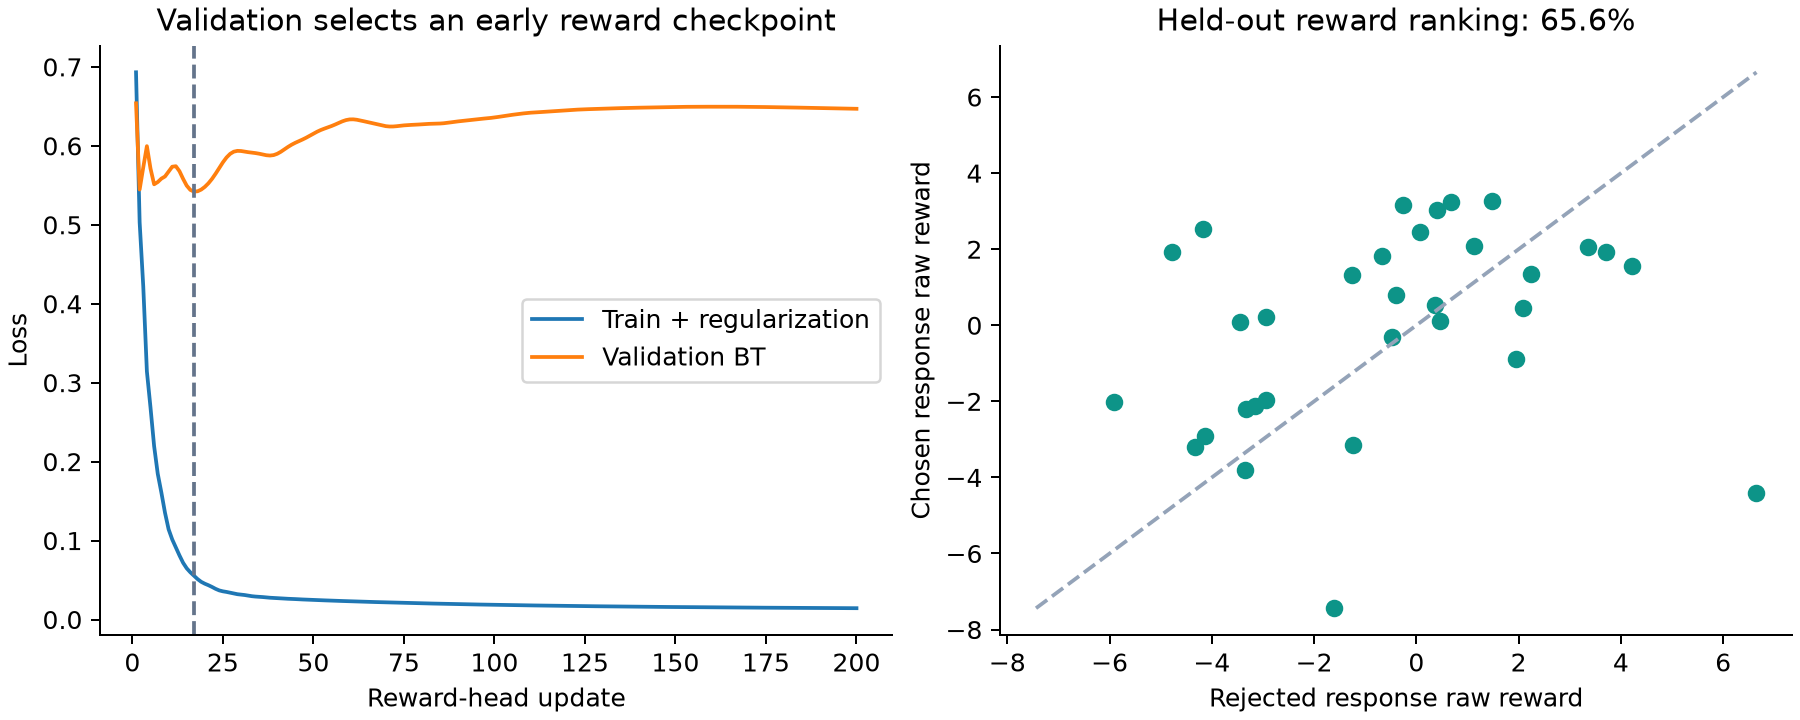

,rollout,id,raw_reward,normalized_reward,sampled_reference_kl,response,response_tokens
0,1,00205669f2094202ce97c3f9dda5ce48375ce3c00479c1...,-2.357942,-0.468391,0.000000,"Besides that, there is a razor line similar to...",24
1,2,001c0a8449b012286234959e57dcda2a2f6fef32dc5235...,-3.842940,-0.879625,0.000487,As an artificial intelligence language model s...,24
2,3,00242c0550d340fb2390a19487825f9b258890207a3887...,-1.656265,-0.274079,0.000211,Indeed. Therefore we make things like real ter...,24
3,4,001dd37548592ae831610ea01ae2d366e44a81fd3e687c...,-6.624526,-1.649918,-0.002589,Absolutely precise description... Tomato Bisqu...,24
4,5,000351c5e38f2b894d27f75e3202a7f6ddd8bc3cf2b25c...,-2.085176,-0.392855,0.001228,I think I’ll try adding a small sprinkle of Pa...,24
5,6,002522152a8610ef2bd3676c866d4c3e7ebade3822fa1e...,-5.565618,-1.356679,0.003793,Sure! Here are a few of the most common indoor...,24


{'n': 32,
 'pairwise_accuracy': 0.65625,
 'ci95': [0.4831108797896222, 0.7958956207556682]}

In [5]:
display(Image(filename=str(ROOT / "reports/figures/reward_model.png")))
display(pd.DataFrame(read("reports/ppo_rollouts.json")))
summary["reward_test"]

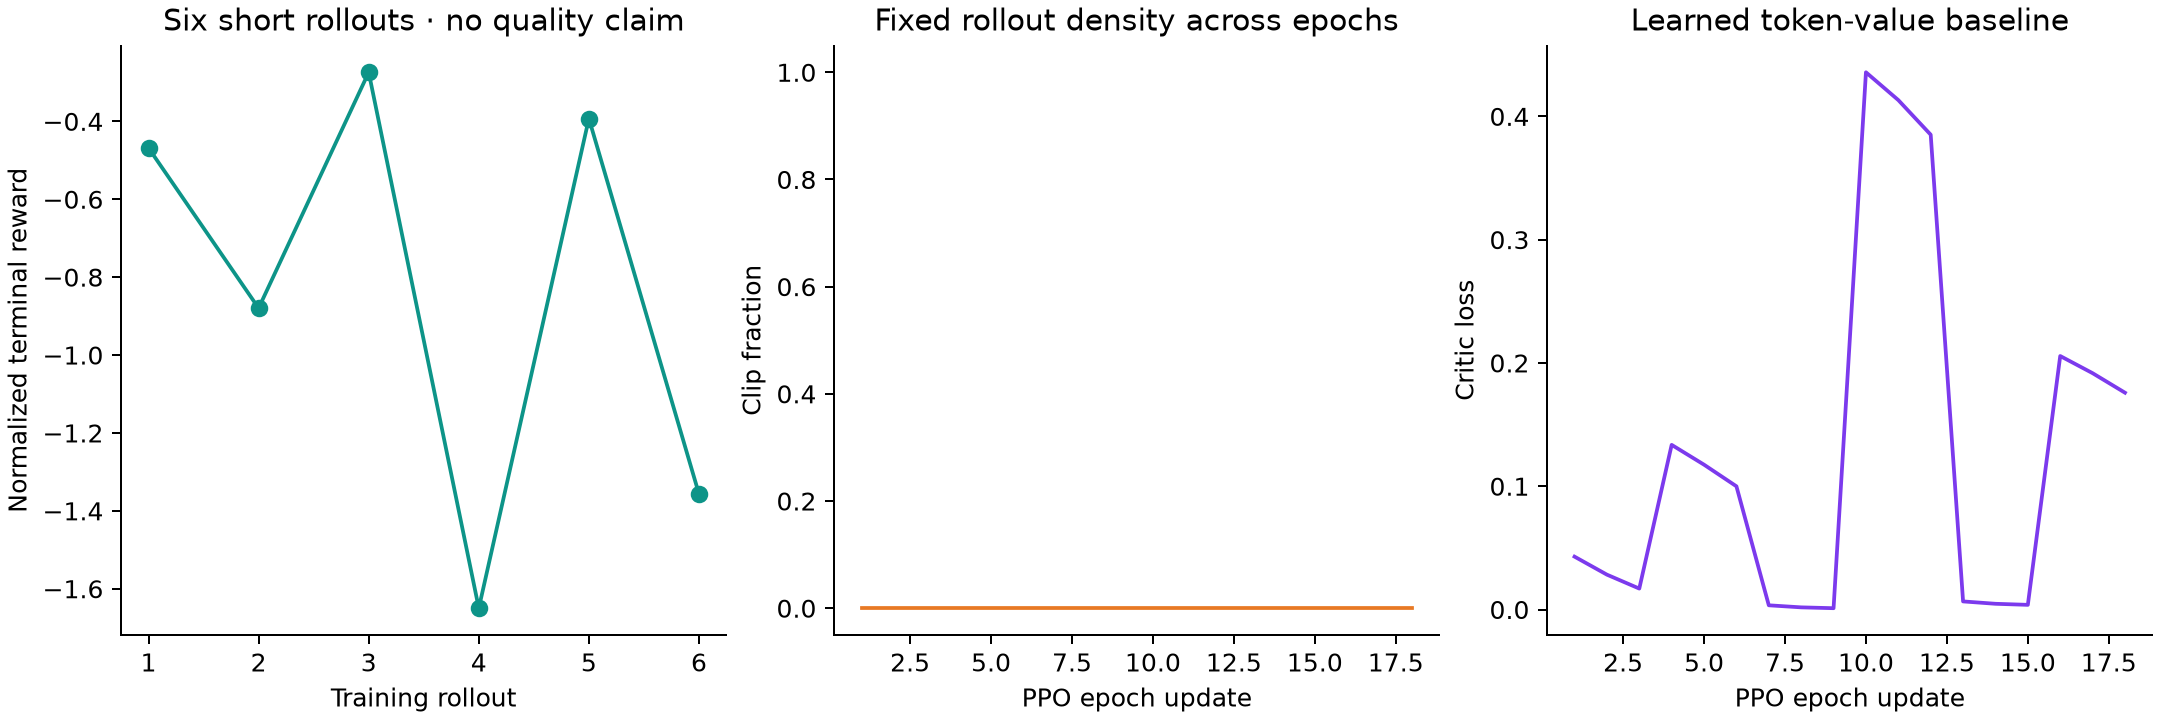

,method,step,loss,rollout,epoch,policy_loss,value_loss,clip_fraction,old_policy_approx_kl
60,ppo,1,0.021441,1.0,1.0,2.980232e-08,0.042882,0.0,0.000000e+00
61,ppo,2,0.007694,1.0,2.0,-6.442179e-03,0.028272,0.0,3.989600e-05
62,ppo,3,-0.004430,1.0,3.0,-1.291672e-02,0.016974,0.0,1.599207e-04
63,ppo,4,0.066776,2.0,1.0,6.953875e-08,0.133551,0.0,0.000000e+00
64,ppo,5,0.051425,2.0,2.0,-7.310063e-03,0.117469,0.0,1.401109e-04
65,ppo,6,0.032334,2.0,3.0,-1.763388e-02,0.099935,0.0,7.955770e-04
66,ppo,7,0.001706,3.0,1.0,1.837810e-07,0.003412,0.0,0.000000e+00
67,ppo,8,-0.003787,3.0,2.0,-4.657244e-03,0.001741,0.0,1.577909e-05
68,ppo,9,-0.010701,3.0,3.0,-1.123142e-02,0.001060,0.0,8.974069e-05
69,ppo,10,0.217876,4.0,1.0,6.953875e-08,0.435751,0.0,0.000000e+00


In [6]:
display(Image(filename=str(ROOT / "reports/figures/ppo_diagnostics.png")))
history = pd.DataFrame(read("reports/training_history.json"))
display(history[history["method"] == "ppo"])
assert summary["reference_adapter_unchanged"]

## Human labels are different from model labels

The source spreadsheet used GPT-4 pair labels. Genuine human annotations are evaluated separately. Invalid outputs count as failures, never as ties. Answer-order swaps expose weak evaluator reliability.

,n,agreement,agreement_ci95,macro_f1,kappa,valid_rate,swap_valid_pairs,swap_consistency,majority_baseline,label_counts
human,12,0.166667,"[0.04696514218385378, 0.4480308622529734]",0.150794,-0.121495,0.916667,11,0.181818,0.416667,"{'A': 3, 'B': 4, 'tie': 5}"
gpt4_reference,12,0.25,"[0.08894166839405471, 0.5323053349335657]",0.222222,0.1,0.75,9,0.555556,0.583333,"{'A': 1, 'B': 7, 'tie': 4}"


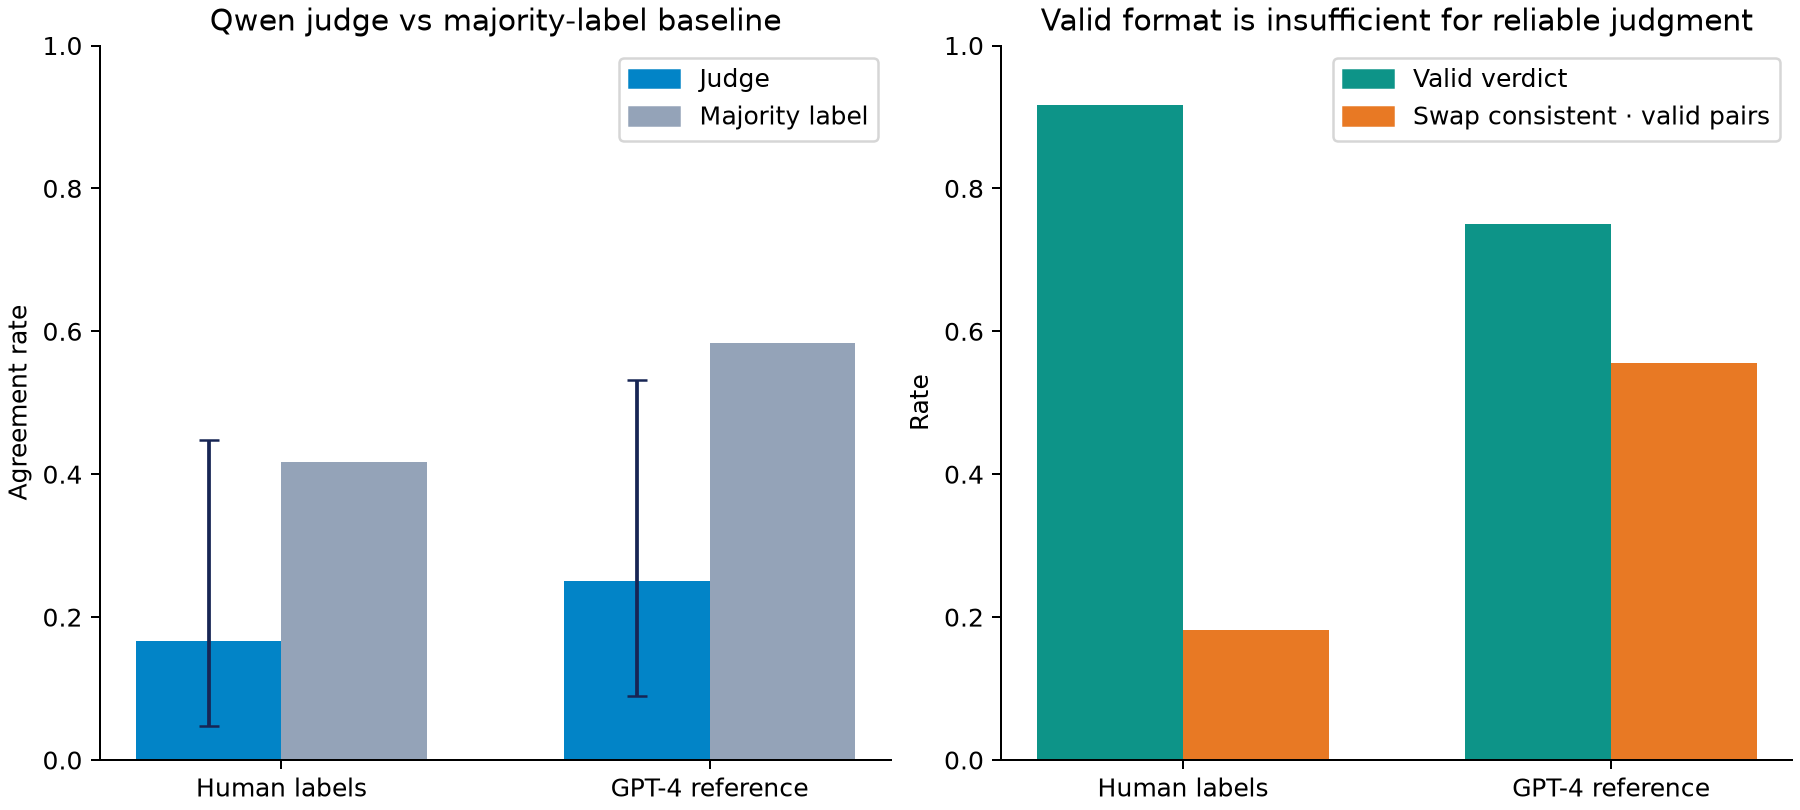

,source,label,raw_output,verdict,swapped_raw_output,swapped_verdict
0,human,B,A,A,A,A
1,human,B,A,A,A,A
2,human,tie,A,A,A,A
3,human,tie,A,A,A,A
4,human,A,Answer A is more detailed and vivid compared,invalid,Answer A: This description is quite vivid,invalid
5,human,B,A,A,A,A
6,human,tie,A,A,TIE,tie
7,human,tie,TIE,tie,TIE,tie
8,human,A,A,A,A,A
9,human,A,TIE,tie,TIE,tie


In [7]:
display(pd.DataFrame(read("reports/judge_summary.json")).T)
display(Image(filename=str(ROOT / "reports/figures/judge_reliability.png")))
judge_rows = pd.DataFrame(read("reports/judge_predictions.json"))
display(
    judge_rows[
        [
            "source",
            "label",
            "raw_output",
            "verdict",
            "swapped_raw_output",
            "swapped_verdict",
        ]
    ]
)

## Bilingual retail-support token costs

Six authored parallel messages provide a compact tokenizer comparison. Fewer tokens may reduce context costs; they do not prove better answers. These cases are not a retail adaptation benchmark.

tokens  characters_per_token
model   language                                 
Llama 2 English    9.833333              4.811953
        Persian   50.166667              0.988816
Llama 3 English    8.833333              5.332870
        Persian   15.000000              3.333283

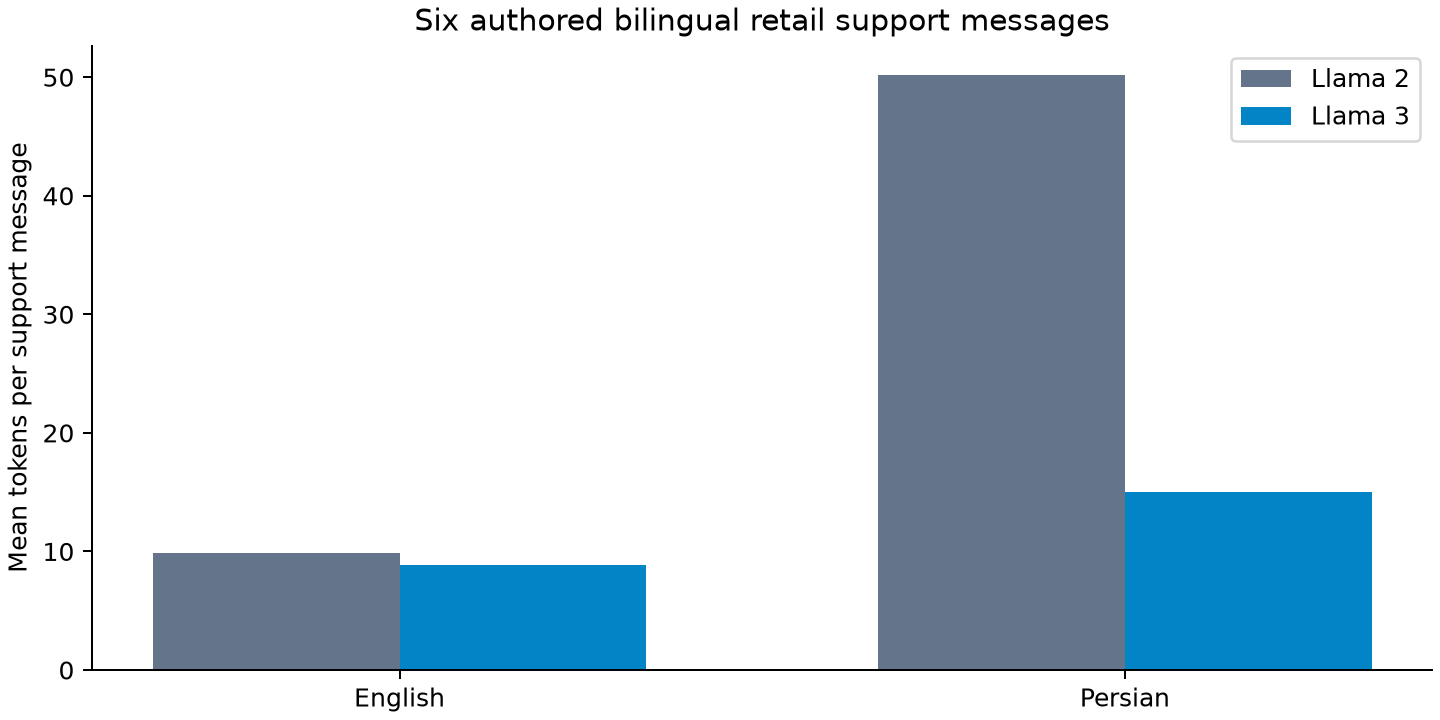

In [8]:
tokens = pd.DataFrame(read("reports/tokenizer_audit.json"))
display(
    tokens.groupby(["model", "language"])[["tokens", "characters_per_token"]].mean()
)
display(Image(filename=str(ROOT / "reports/figures/bilingual_token_cost.png")))

## Artifact portability and decision

The exported DPO adapter is independently reloaded and compared against recorded held-out likelihoods. The engineering pipeline is reproducible, but these results do not authorize a production model or automated judge release.

In [9]:
verification = read("reports/reload_verification.json")
assert verification["passed"]
verification

{'adapter': 'dpo',
 'heldout_pairs': 2,
 'max_absolute_logp_difference': 0.0,
 'passed': True}